# Predicción completa

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import joblib

from datetime import datetime

In [2]:
# Definiciones globales y funciones de transformación

%run ../Lib/pandas_options.py
%run ../Lib/define_constantes.py
%run ../Lib/fn_transformaciones.py

Fecha y Hora de ejecución de módulo: 2024-11-09 14:16:54


In [3]:
# Cargar archivo de tramos

archivo_tramos = f'{DIRECTORIO_DATOS}/DATOSTRAMOS_2024-10.csv'
df_tramos = pd.read_csv(archivo_tramos, low_memory=False)

In [4]:
# Corregir nombres de columnas 

df_tramos.columns = [col.split(',')[0] for col in df_tramos.columns]
print(df_tramos.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 221024 entries, 0 to 221023
Data columns (total 79 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   G3E_STYLEI  221024 non-null  int64  
 1   G3E_FNO     221024 non-null  int64  
 2   G3E_CNO     221024 non-null  int64  
 3   G3E_FID     221024 non-null  int64  
 4   G3E_CID     221024 non-null  int64  
 5   G3E_ID      221024 non-null  int64  
 6   DIAMETRO    221024 non-null  int64  
 7   CAMARA_CAI  221024 non-null  object 
 8   CONEXIONES  199642 non-null  object 
 9   MATERIAL    220587 non-null  object 
 10  TUBERIA_EL  206776 non-null  object 
 11  VIDA_UTIL   207362 non-null  float64
 12  FABRICANTE  203489 non-null  object 
 13  TIPO_CIMEN  91060 non-null   object 
 14  TIPO_SUELO  72833 non-null   object 
 15  TIPO_RED    221024 non-null  object 
 16  PROF_BATEA  218241 non-null  float64
 17  PROF_BATE1  218048 non-null  float64
 18  COTA_BATEA  216747 non-null  float64
 19  CO

In [5]:
# Cargar modelo

archivo_modelo = f'{DIRECTORIO_MODELOS}/modelo.joblib'
modelo = joblib.load(archivo_modelo)
print(modelo)

LogisticRegression(C=5,
                   class_weight={False: 1,
                                 True: np.float64(1.2031437966156067)},
                   n_jobs=-1, solver='newton-cholesky')


In [6]:
# Cargar columnas

columnas_modelo = []
archivo_columnas = f'{DIRECTORIO_MODELOS}/COLUMNAS.txt'

with open(archivo_columnas, "r") as archivo:
    for linea in archivo:
        cadena = linea.strip()
        columnas_modelo.append(cadena)

print(columnas_modelo)

['EDAD', 'DIAMETRO', 'LONGITUD', 'AREA', 'PROF_BATEA', 'PROF_BATE1', 'PENDIENTE', 'ARRANQUE', 'ZONA_SUR', 'MUNICIPIO_MEDELLIN', 'ESTADO_OPERACION', 'TIPO_AGUA_COMBINADAS', 'TIPO_AGUA_LLUVIAS Y DESCARGAS', 'TIPO_AGUA_OTRAS', 'MATERIAL_CONCRETO REFORZADO Y OTROS', 'MATERIAL_CONCRETO SIMPLE', 'MATERIAL_PVC', 'FABRICANTE_INDUSTRIAS DIQUE S.A.', 'FABRICANTE_MEXICHEM COLOMBIA S.A.S.', 'FABRICANTE_OTROS']


In [7]:
# Generar set de datos

df_predecir = df_tramos.copy()

# Agregar columnas dummy para codificacion
df_predecir['CALIFICACION'] = 1 # Irrelevante, no se usa pero es requerido para transformacion
df_predecir['FECHA_CALIFICACION'] = datetime.now()

X_predecir = tx_codificar(tx_aplicar_transformaciones(df_predecir))

# Agregar columnas faltantes
for col in columnas_modelo:
    if col not in X_predecir.columns:
        print(f'Agregando {col}')
        X_predecir[col] = False

# Reordenar columnas
X_predecir = X_predecir[columnas_modelo]

# Obtener tramos asociados
ipids = df_predecir.loc[df_predecir.index.isin(X_predecir.index)]['IPID']

print(X_predecir.info())
#print(df_ipids.info())

Aplicando transformación: Depurar datos nulos         ... Terminada.
Aplicando transformación: Convertir tipo de datos     ... Terminada.
Aplicando transformación: Validar rango de datos      ... Terminada.
Aplicando transformación: Unificar unidades a metros  ... Terminada.
Aplicando transformación: Reasignar arranque          ... Terminada.
Aplicando transformación: Reasignar tipo de agua      ... Terminada.
Aplicando transformación: Reasignar materiales        ... Terminada.
Aplicando transformación: Reasignar fabricantes       ... Terminada.
Aplicando transformación: Reasignar zonas             ... Terminada.
Aplicando transformación: Reasignar municipios        ... Terminada.
Aplicando transformación: Reasignar estados           ... Terminada.
Aplicando transformación: Agregar edad de tramos      ... Terminada.
Aplicando transformación: Aregar área de tramos       ... Terminada.
Aplicando transformación: Recalcular pendientes       ... Terminada.
Aplicando transformación: Binariza

In [8]:
# Calcular probabilidades

probabilidades = modelo.predict_proba(X_predecir)
probabilidades_deterioro = probabilidades[:, 1]

df_probabilidades = pd.DataFrame({'IPID': ipids, 'PROBABILIDAD_DETERIORO': probabilidades_deterioro}).sort_values(by='PROBABILIDAD_DETERIORO', ascending=False) 

display(df_probabilidades)

,IPID,PROBABILIDAD_DETERIORO
97493,6228773,0.990803
141792,6249982,0.989916
69611,6232722,0.989317
100437,6197795,0.987828
136222,6204644,0.985080
...,...,...
41906,10179320,0.032675
42141,10274474,0.032539
41926,10179368,0.031904
41925,10179366,0.030651


In [9]:
# Guardar reporte

print("Fecha y Hora de ejecución de módulo:", fecha_hora_formateada)
archivo_predicciones_completo = f'{DIRECTORIO_RESULTADOS}/PREDICCIONES_COMPLETAS_{datetime.now().strftime('%Y-%m-%d')}.csv'

df_probabilidades.to_csv(archivo_predicciones_completo, index=False)

Fecha y Hora de ejecución de módulo: 2024-11-09 14:16:54


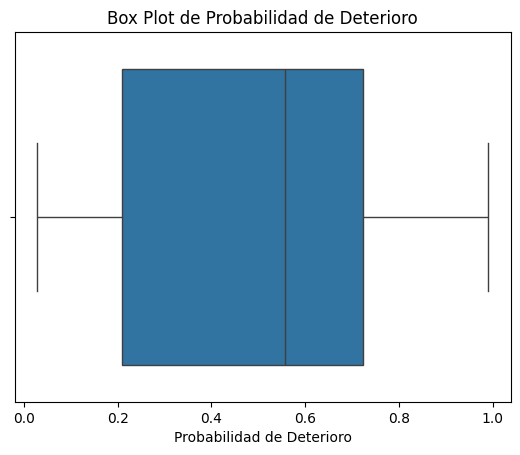

In [10]:
# Visualizar distribución de probabilidad

sns.boxplot(data=df_probabilidades, x='PROBABILIDAD_DETERIORO')
plt.xlabel('Probabilidad de Deterioro')
plt.title('Box Plot de Probabilidad de Deterioro')
plt.show()